WEEK 7 – FEATURE SELECTION AND PCA

Objective:
To identify important features and reduce the dimensionality of the dataset using Principal Component Analysis (PCA).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving mental_health_in_tech_2016.csv to mental_health_in_tech_2016.csv


In [7]:
import pandas as pd

file_name = next(iter(uploaded))
encoded_data = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", encoded_data.shape)
display(encoded_data.head())

Dataset Loaded Successfully!
Dataset Shape: (1433, 63)


,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,...,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,...,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,...,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,43,male,United Kingdom,NaN,United Kingdom,NaN,Supervisor/Team Lead,Sometimes
4,0,6-25,0.0,1.0,Yes,Yes,No,No,No,Neither easy nor difficult,...,Sometimes,Sometimes,43,Female,United States of America,Illinois,United States of America,Illinois,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes


In [8]:
import numpy as np

X = encoded_data.select_dtypes(include=np.number).copy()

X = X.fillna(X.median())

print("Numerical Dataset Shape:", X.shape)
display(X.head())

Numerical Dataset Shape: (1433, 7)


,Are you self-employed?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,Do you have previous employers?,Have you ever sought treatment for a mental health issue from a mental health professional?,What is your age?
0,0,1.0,1.0,1.0,1,0,39
1,0,1.0,1.0,1.0,1,1,29
2,0,1.0,1.0,1.0,1,1,38
3,1,1.0,1.0,1.0,1,1,43
4,0,0.0,1.0,1.0,1,1,43


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standard Scaling Completed!")
print("Scaled Data Shape:", X_scaled.shape)

Standard Scaling Completed!
Scaled Data Shape: (1433, 7)


In [10]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("PCA Completed Successfully!")
print("PCA Data Shape:", X_pca.shape)

PCA Completed Successfully!
PCA Data Shape: (1433, 7)


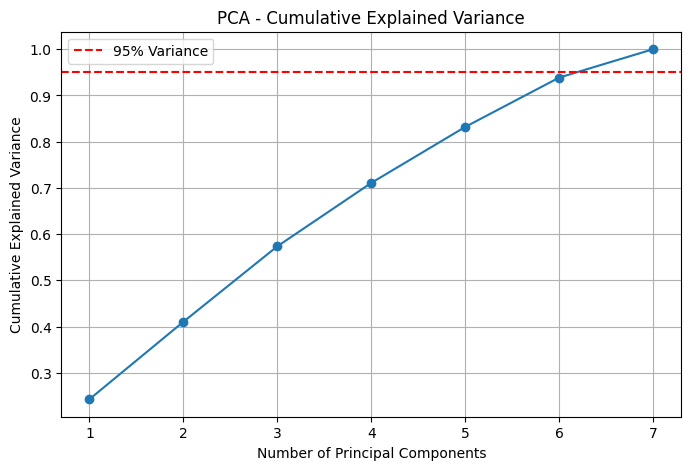

In [11]:
import matplotlib.pyplot as plt
import numpy as np

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(y=0.95, color='red', linestyle='--',
            label='95% Variance')

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.legend()
plt.grid()
plt.show()

In [12]:
indices = np.where(cumulative_variance >= 0.95)[0]

if len(indices) > 0:
    components_95 = indices[0] + 1
else:
    components_95 = len(cumulative_variance)

print("Components Required for 95% Variance:", components_95)
print("Total Components:", len(cumulative_variance))

Components Required for 95% Variance: 7
Total Components: 7


In [13]:
import pandas as pd

pca_columns = [f"PC{i+1}" for i in range(X_pca.shape[1])]

pca_data = pd.DataFrame(
    X_pca,
    columns=pca_columns
)

print("Final PCA Dataset:")
display(pca_data.head())

pca_data.to_csv("Week7_PCA_Data.csv", index=False)

print("Week 7 Completed Successfully!")
print("File Saved: Week7_PCA_Data.csv")

Final PCA Dataset:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-0.304705,-0.295236,0.112760,-1.357138,0.216227,0.398597,-0.206970
1,-0.305219,-0.383163,0.806161,0.736270,0.260468,0.228557,-0.267245
2,-0.199410,0.075419,0.993975,0.380355,-0.193833,0.433752,-0.329501
3,1.487419,0.673579,0.763691,0.347281,-0.292377,0.424203,1.451676
4,-1.138345,1.515344,0.413573,0.326860,-0.780778,-1.319002,0.068412


Week 7 Completed Successfully!
File Saved: Week7_PCA_Data.csv


In [14]:
from google.colab import files

files.download("Week7_PCA_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>